In [1]:
#Deliverable 1

In [2]:
##Binary Classification

In [3]:
#import das bibliotecas
import os, glob, hashlib, time, warnings 
#warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import imageio.v3 as iio
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)
from tensorflow.keras.layers import Dense
 
print("TensorFlow imported successfully:", tf.__version__)

print("GPU available:", tf.config.list_physical_devices("GPU") or "No (training will run on CPU, it is slower but works)")

TensorFlow imported successfully: 2.22.0-rc0
GPU available: No (training will run on CPU, it is slower but works)


In [4]:
#mencao do caminho aonde buscar, criacao das classes que iremos classificar e validacao de tudo que estiver dentro da pasta
import pathlib
files = r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\project pictures"

data_dir = pathlib.Path(files)

classificacoes = {"Painting", "Photo", "Schematics", "Sketch", "Text"}
classificacoes_binary = {"Photo"}

if (data_dir / "Data Science Project").exists():
    data_dir = data_dir / "Data Science Project"

print (data_dir)
print (sorted(p.name for p in data_dir.iterdir() if p.is_dir()))

C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\project pictures
['Painting', 'Photo', 'Schematics', 'Sketch', 'Text']


In [5]:
#definicao dos tamanhos das imagens e do % que iremos treinar e validar
image_h = 180
image_w = 180
batch_s = 32

# The train_set
training_set = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  validation_split= 0.15,
  subset = "training",
  seed=42,
  image_size =(image_h, image_w),
  batch_size = batch_s
)
# The test_set
testing_set = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  validation_split= 0.15,
  subset = "validation",
  seed=42,
  image_size =(image_h, image_w),
  batch_size = batch_s
)

Found 41406 files belonging to 5 classes.
Using 35196 files for training.
Found 41406 files belonging to 5 classes.
Using 6210 files for validation.


In [6]:
print("Pastas dentro de data_dir:")

for p in data_dir.iterdir():
    if p.is_dir():
        print("-", p.name)

Pastas dentro de data_dir:
- Painting
- Photo
- Schematics
- Sketch
- Text


In [7]:
## data exploration and visualization

In [8]:
#definicao das classes que quero ver
# 5 pastas -> 2 classes: 1 = Photo, 0 = Not Photo
classificacoes = sorted(p.name for p in data_dir.iterdir() if p.is_dir())   # same order as image_dataset_from_directory
print(classificacoes)
 
photo_index = classificacoes.index("Photo")
 
def to_binary(images, labels):
    # 1 se a imagem vem da pasta Photo, 0 caso contrário
    return images, tf.cast(tf.equal(labels, photo_index), tf.float32)
 
training_set = training_set.map(to_binary)
testing_set = testing_set.map(to_binary)
 
images, labels = next(iter(training_set))
print("Formato das imagens:", images.shape)
print("Formato dos labels:", labels.shape)
print("Labels do primeiro batch:", labels.numpy().astype(int))   # só 0 e 1

['Painting', 'Photo', 'Schematics', 'Sketch', 'Text']


Formato das imagens: (32, 180, 180, 3)
Formato dos labels: (32,)
Labels do primeiro batch: [0 0 1 0 0 0 1 1 0 0 1 0 1 0 0 1 1 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0]


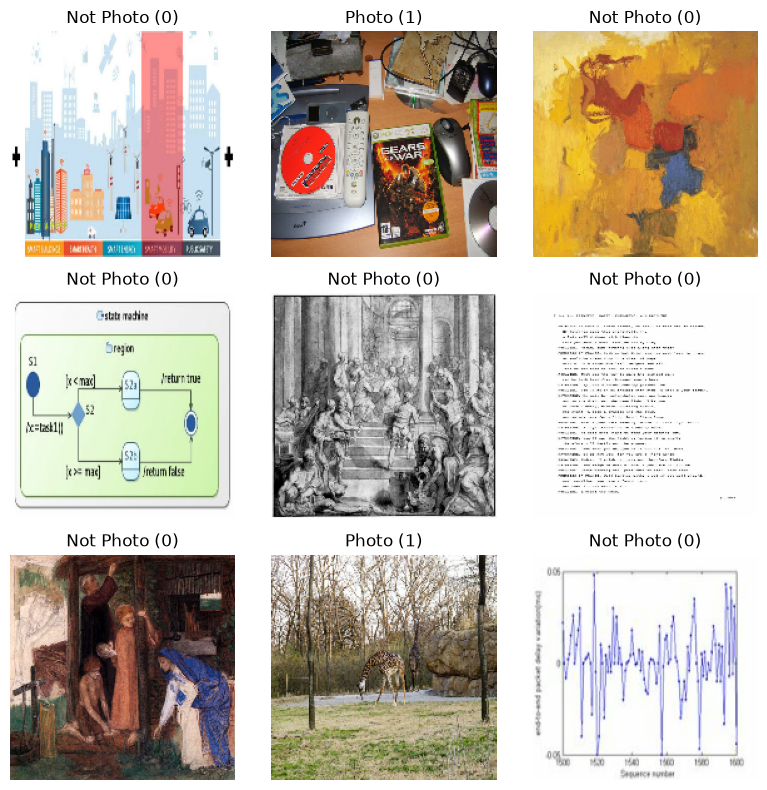

In [9]:
#visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
for images, labels in training_set.take(1):
    # Get the actual number of images in the batch (minimum of 9 or batch size)
    num_images = min(9, len(images))
    
    for i in range(num_images):
        ax = plt.subplot(3, 3, i + 1)
        label = int(labels[i].numpy())
        title = "Photo (1)" if label == 1 else "Not Photo (0)"
        plt.title(title)
        #if label == 1:
          #  plt.title("photo")
       # else:
          #  plt.title("no photo")
        plt.axis("off")
        plt.imshow(images[i].numpy().astype("uint8"))
        
plt.tight_layout()
plt.show()
#images[i] → pega a imagem i
#.numpy() → transforma o tensor do TensorFlow em array NumPy
        #subplot define quantas fotos vamos ver considerando o Y e o X do quadrado
#.astype("uint8") → converte os valores para o formato usual de imagem
#plt.imshow() → mostra a imagem

In [10]:
AUTOTUNE = tf.data.AUTOTUNE
 
training_set = training_set.cache().shuffle(1000, seed=42).prefetch(buffer_size=AUTOTUNE)
testing_set = testing_set.cache().prefetch(buffer_size=AUTOTUNE)
 
print("Classificação binária configurada: 0 = Not Photo; 1 = Photo")

Classificação binária configurada: 0 = Not Photo; 1 = Photo


In [11]:
# Recriar o modelo para classificação binária
num_classes = 1

pictures_model = Sequential([
    #normalization
    layers.Input(shape=(image_h, image_w, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [12]:
# Option 1: Build the model explicitly with input shape
#pictures_model.build(input_shape=(None, 224, 224, 3))  # Replace with your actual input dimensions

pictures_model.compile(optimizer="adam",
              loss=tf.keras.losses.BinaryCrossentropy(),   # saída sigmoid -> binary cross-entropy
              metrics=["accuracy"])
 
pictures_model.summary()
 
print("Saída do modelo:", pictures_model.output_shape)   # deve ser (None, 1)
print("Função de perda:", pictures_model.loss)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,988,769 (15.22 MB)

 Trainable params: 3,988,769 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

Saída do modelo: (None, 1)
Função de perda: <LossFunctionWrapper(<function binary_crossentropy at 0x00000247387CD590>, kwargs={'from_logits': False, 'label_smoothing': 0.0, 'axis': -1})>


In [13]:
print(type(training_set))
images, labels = next(iter(training_set))
print(images.shape)
print(labels.shape)

<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
(32, 180, 180, 3)
(32,)


In [14]:
# regularization techniques (considering overfitting):
# data argumentation - rotation of the image, and zoom
# drop-out
# early-stopping

Epoch 1/10


c:\Users\ferge\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1100/1100 ━━━━━━━━━━━━━━━━━━━━ 144s 79ms/step - accuracy: 0.8467 - loss: 0.3154 - val_accuracy: 0.8820 - val_loss: 0.2555
Epoch 2/10
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 86s 78ms/step - accuracy: 0.9013 - loss: 0.2244 - val_accuracy: 0.9103 - val_loss: 0.2089
Epoch 3/10
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 84s 76ms/step - accuracy: 0.9309 - loss: 0.1696 - val_accuracy: 0.8847 - val_loss: 0.2682
Epoch 4/10
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 79s 72ms/step - accuracy: 0.9495 - loss: 0.1254 - val_accuracy: 0.9113 - val_loss: 0.2137
Epoch 5/10
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 78s 71ms/step - accuracy: 0.9691 - loss: 0.0833 - val_accuracy: 0.9174 - val_loss: 0.2250
Epoch 6/10
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 86s 79ms/step - accuracy: 0.9809 - loss: 0.0517 - val_accuracy: 0.9161 - val_loss: 0.2739
Epoch 7/10
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 71s 65ms/step - accuracy: 0.9900 - loss: 0.0286 - val_accuracy: 0.9113 - val_loss: 0.3317
Epoch 8/10
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 69s 63ms/step - accuracy: 0.9923 - loss: 0.0

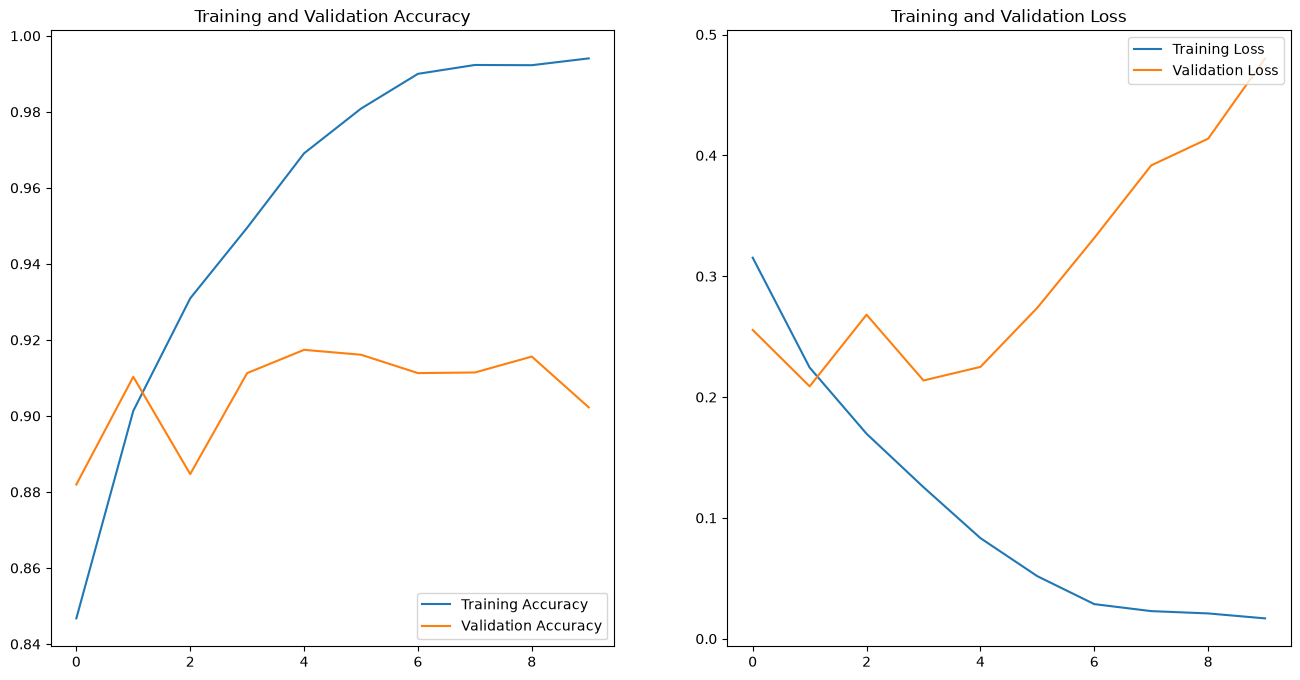

In [15]:
# First, define the number of epochs
epochs = 10  # You can change this to your desired number of training epochs
history_pictures = pictures_model.fit(training_set, validation_data=testing_set, epochs=epochs)

acc = history_pictures.history['accuracy']
val_acc = history_pictures.history['val_accuracy']

loss = history_pictures.history['loss']
val_loss = history_pictures.history['val_loss']

epochs_range = range(epochs)

# Import matplotlib if not already imported
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [16]:
print("Saída do modelo:", pictures_model.output_shape)

Saída do modelo: (None, 1)


dog.jpeg             -> Photo      (97.7%)
moodle.png           -> Not Photo  (100.0%)
monalisa.jpg         -> Not Photo  (100.0%)
1.jpg                -> Not Photo  (80.6%)
2.jpg                -> Photo      (73.7%)
3.jpg                -> Not Photo  (100.0%)
4.jpg                -> Not Photo  (100.0%)
5.jpg                -> Not Photo  (100.0%)
hotdog.jpeg          -> Photo      (100.0%)


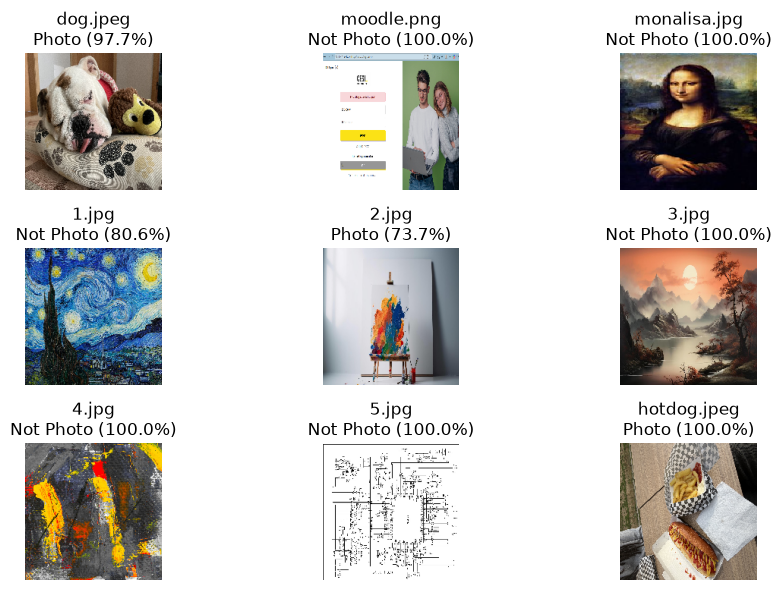

In [17]:
#teste com minhas imagens

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import math

new_image_paths = [
    r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste\dog.jpeg",
    r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste\moodle.png",
    r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste\monalisa.jpg",
    r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste\1.jpg",
    r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste\2.jpg",
    r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste\3.jpg",
    r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste\4.jpg",
    r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste\5.jpg",
    r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste\hotdog.jpeg"
]

valid_paths = [Path(p) for p in new_image_paths if Path(p).exists()]
missing_paths = [Path(p) for p in new_image_paths if not Path(p).exists()]

for path in missing_paths:
    print("Imagem não encontrada:", path.name)

if not valid_paths:
    print("Nenhuma imagem foi encontrada. Confira os caminhos.")

else:
    cols = 3
    rows = math.ceil(len(valid_paths) / cols)

    plt.figure(figsize=(10, 2 * rows))

    for i, path in enumerate(valid_paths):
        img = tf.keras.utils.load_img(
            path,
            target_size=(image_h, image_w)
        )

        x = tf.keras.utils.img_to_array(img)
        x = tf.expand_dims(x, axis=0)

        # A saída sigmoid já é uma probabilidade.
        photo_probability = float(
            pictures_model.predict(x, verbose=0)[0][0]
        )

        if photo_probability >= 0.5:
            result = "Photo"
            confidence = photo_probability
        else:
            result = "Not Photo"
            confidence = 1 - photo_probability

        print(
            f"{path.name:<20} -> {result:<10} "
            f"({confidence:.1%})"
        )

        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"{path.name}\n{result} ({confidence:.1%})")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [18]:
print("Acurácia final de treinamento:",
      f"{history_pictures.history['accuracy'][-1]:.2%}")

print("Acurácia final de validação:",
      f"{history_pictures.history['val_accuracy'][-1]:.2%}")

Acurácia final de treinamento: 99.41%
Acurácia final de validação: 90.23%


In [19]:
print("Classes originais:", classificacoes_binary)

for class_name in classificacoes_binary:
    folder = data_dir / class_name
    total = sum(1 for p in folder.iterdir() if p.is_file())
    print(f"{class_name}: {total} imagens")

Classes originais: {'Photo'}
Photo: 9993 imagens


In [20]:
print("Saída do modelo:", pictures_model.output_shape)

Saída do modelo: (None, 1)


#DELIVERABLE 2

In [21]:
#Deliverable 2

In [22]:
##Denoising

In [23]:
files2 = r"G:\My Drive\CESI\Dataset Livrable 2\Dataset"
noisy_dir = pathlib.Path(files2)
if (noisy_dir / "Dataset").exists():
    noisy_dir = noisy_dir / "Dataset"
print (noisy_dir)

G:\My Drive\CESI\Dataset Livrable 2\Dataset


In [24]:
print("Image height:", image_h),
print("Image width:", image_w),
print("Batch size:", batch_s),
channels = 3 # this dataset contains RGB images
print("Number of channels:", channels)

Image height: 180
Image width: 180
Batch size: 32
Number of channels: 3


In [25]:
# Load all images from the dataset
images = tf.keras.utils.image_dataset_from_directory(
    noisy_dir,
    labels=None,
    image_size=(image_h, image_w),
    batch_size=32,
    color_mode="rgb",
    shuffle=True,
    seed=False
)

Found 148 files.


In [26]:
# Normalize pixel values from [0, 255] to [0, 1]
normalization_layer = tf.keras.layers.Rescaling(1.0/255.0)
images = images.map(normalization_layer)

In [30]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Load images in order, without shuffling
images = tf.keras.utils.image_dataset_from_directory(
    noisy_dir,
    labels=None,
    image_size=(image_h, image_w),
    batch_size=32,
    color_mode="rgb",
    shuffle=False
)

# Normalize pixel values from [0, 255] to [0, 1]
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255.0)
images = images.map(normalization_layer)

# Display images
def display_image(X, n=10):
    n = min(n, len(X))
    plt.figure(figsize=(15, 3))

    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(X[i])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

Found 148 files.


Batch shape: (32, 180, 180, 3)
Minimum: 0.0
Maximum: 1.0


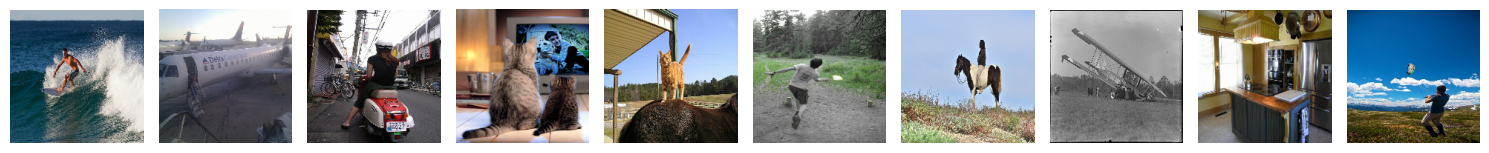

Original training images: (148, 180, 180, 3)
Noisy training images: (148, 180, 180, 3)


In [32]:
# Verify normalization and display the first 10 images
for image_batch in images.take(1):
    print("Batch shape:", image_batch.shape)
    print("Minimum:", float(tf.reduce_min(image_batch)))
    print("Maximum:", float(tf.reduce_max(image_batch)))

    display_image(image_batch.numpy(), n=10)

# Use all images for training
x_train_deliverable2 = np.concatenate(
    [image_batch.numpy() for image_batch in images],
    axis=0
)
print("Original training images:", x_train_deliverable2.shape)

# Add Gaussian noise
noise_factor = 0.5
x_train_noisy_deliverable2 = x_train_deliverable2 + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=x_train_deliverable2.shape
)

# Keep pixel values between 0 and 1
x_train_noisy_deliverable2 = np.clip(x_train_noisy_deliverable2, 0., 1.)
print("Noisy training images:", x_train_noisy_deliverable2.shape)

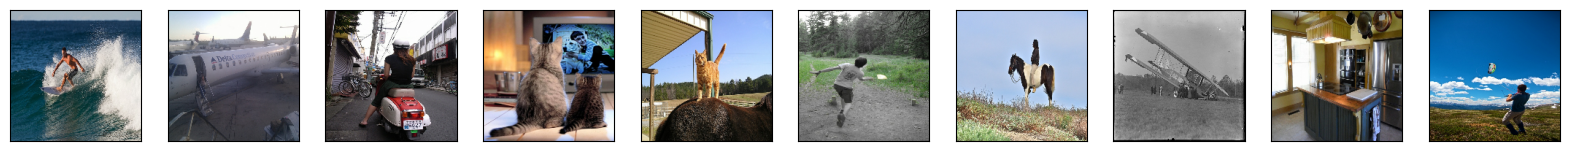

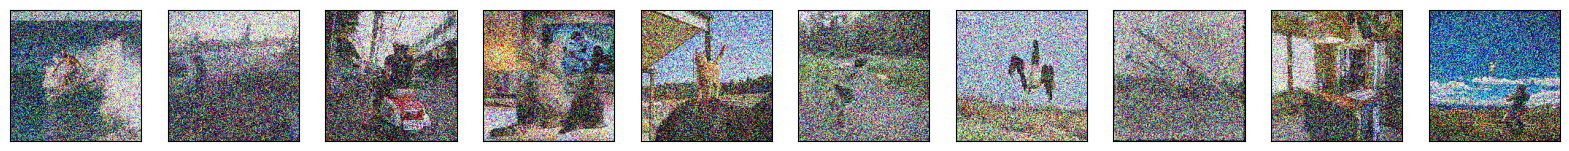

In [ ]:
display_image(x_train_deliverable2[:10], 10)
display_image(x_train_noisy_deliverable2[:10], 10)

In [33]:
from keras.layers import Input, Dense, Conv2D, MaxPooling2D, UpSampling2D
# The encoding process
input_img = Input(shape=(180, 180, 3))

In [34]:
# Encoding

# Conv1: Learn basic image features
x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)

# Reduce spatial dimensions
x = MaxPooling2D((2, 2), padding='same')(x)

# Conv2: Learn more complex features
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)

# Create the encoded representation
encoded = MaxPooling2D((2, 2), padding='same')(x)

In [35]:
# Decoding
# Reconstruct the original image from the encoded representation

# DeConv1
x = Conv2D(32, (3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D((2, 2))(x)

# DeConv2
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)

# DeConv3
decoded = Conv2D(3, (3, 3), activation='sigmoid', padding='same')(x)

In [36]:
from tensorflow.keras.models import Model

# Declare the model
autoencoder = Model(input_img, decoded)

# Compile the model
autoencoder.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Display the model architecture
autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 90, 90, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 180, 180, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,507 (115.26 KB)

 Trainable params: 29,507 (115.26 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

In [38]:
#training the autoencoder to remove noise
history_deliverable2 = autoencoder.fit(
    x_train_noisy_deliverable2,
    x_train_deliverable2,
    epochs=100,
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 580ms/step - accuracy: 0.3816 - loss: 0.6954 - val_accuracy: 0.4417 - val_loss: 0.6909
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 261ms/step - accuracy: 0.4649 - loss: 0.6878 - val_accuracy: 0.4394 - val_loss: 0.6784
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 238ms/step - accuracy: 0.4490 - loss: 0.6720 - val_accuracy: 0.4038 - val_loss: 0.6483
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 223ms/step - accuracy: 0.4397 - loss: 0.6360 - val_accuracy: 0.4386 - val_loss: 0.5897
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 231ms/step - accuracy: 0.4244 - loss: 0.5871 - val_accuracy: 0.3915 - val_loss: 0.5640
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 232ms/step - accuracy: 0.3618 - loss: 0.5853 - val_accuracy: 0.5241 - val_loss: 0.5651
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 235ms/step - accuracy: 0.4636 - loss: 0.5797 - val_accuracy: 0.5263 - val_loss: 0.5529
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 231ms/step - accuracy: 0.4168 - loss: 0.5728 - val_accuracy: 0.4936 - v

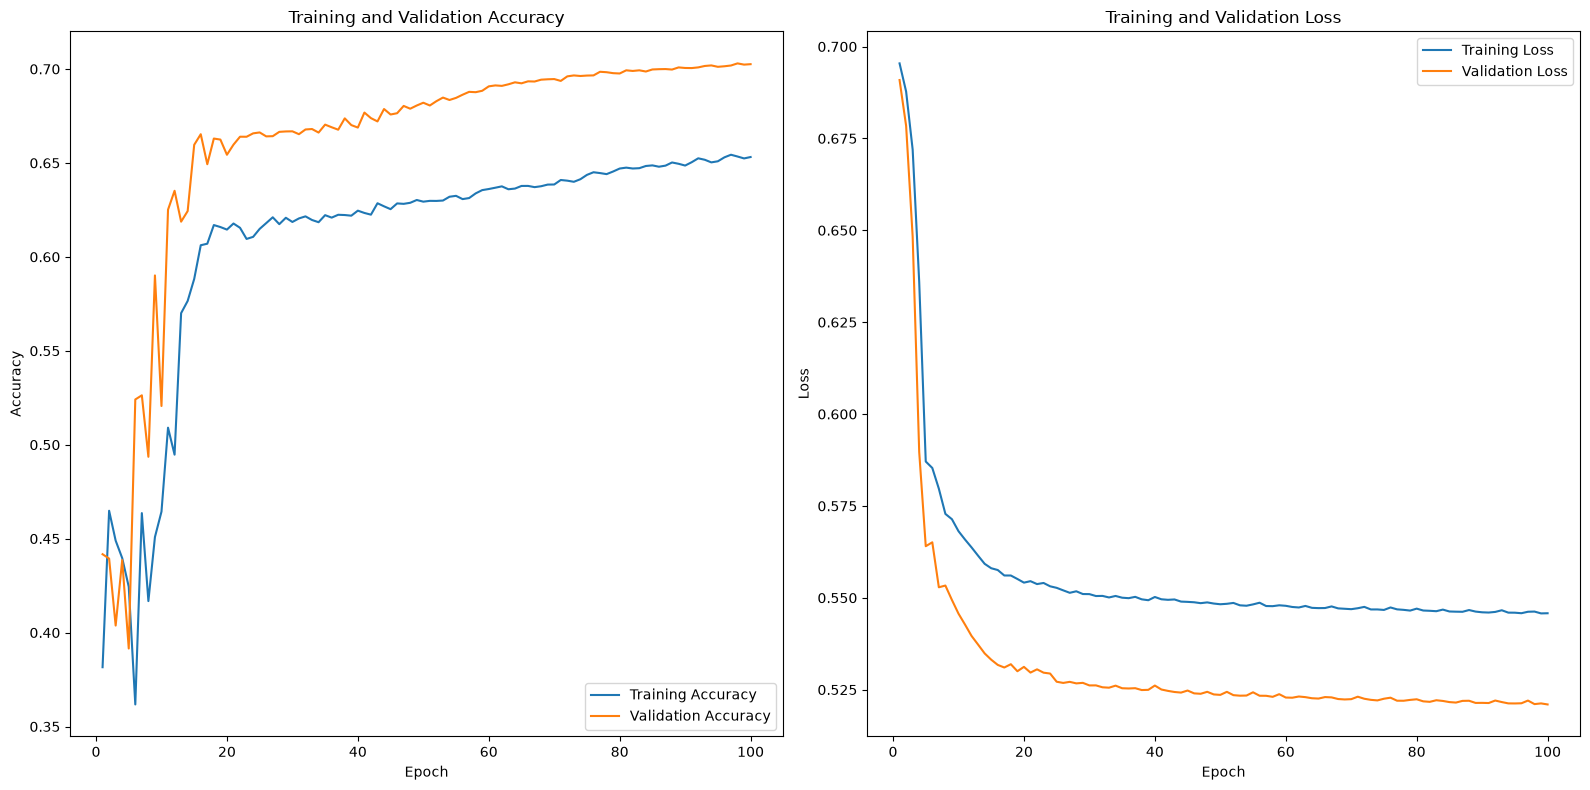

In [39]:
import matplotlib.pyplot as plt

acc = history_deliverable2.history['accuracy']
val_acc = history_deliverable2.history['val_accuracy']

loss = history_deliverable2.history['loss']
val_loss = history_deliverable2.history['val_loss']

epochs_range = range(1, len(loss) + 1)

plt.figure(figsize=(16, 8))

# Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

# Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 518ms/step


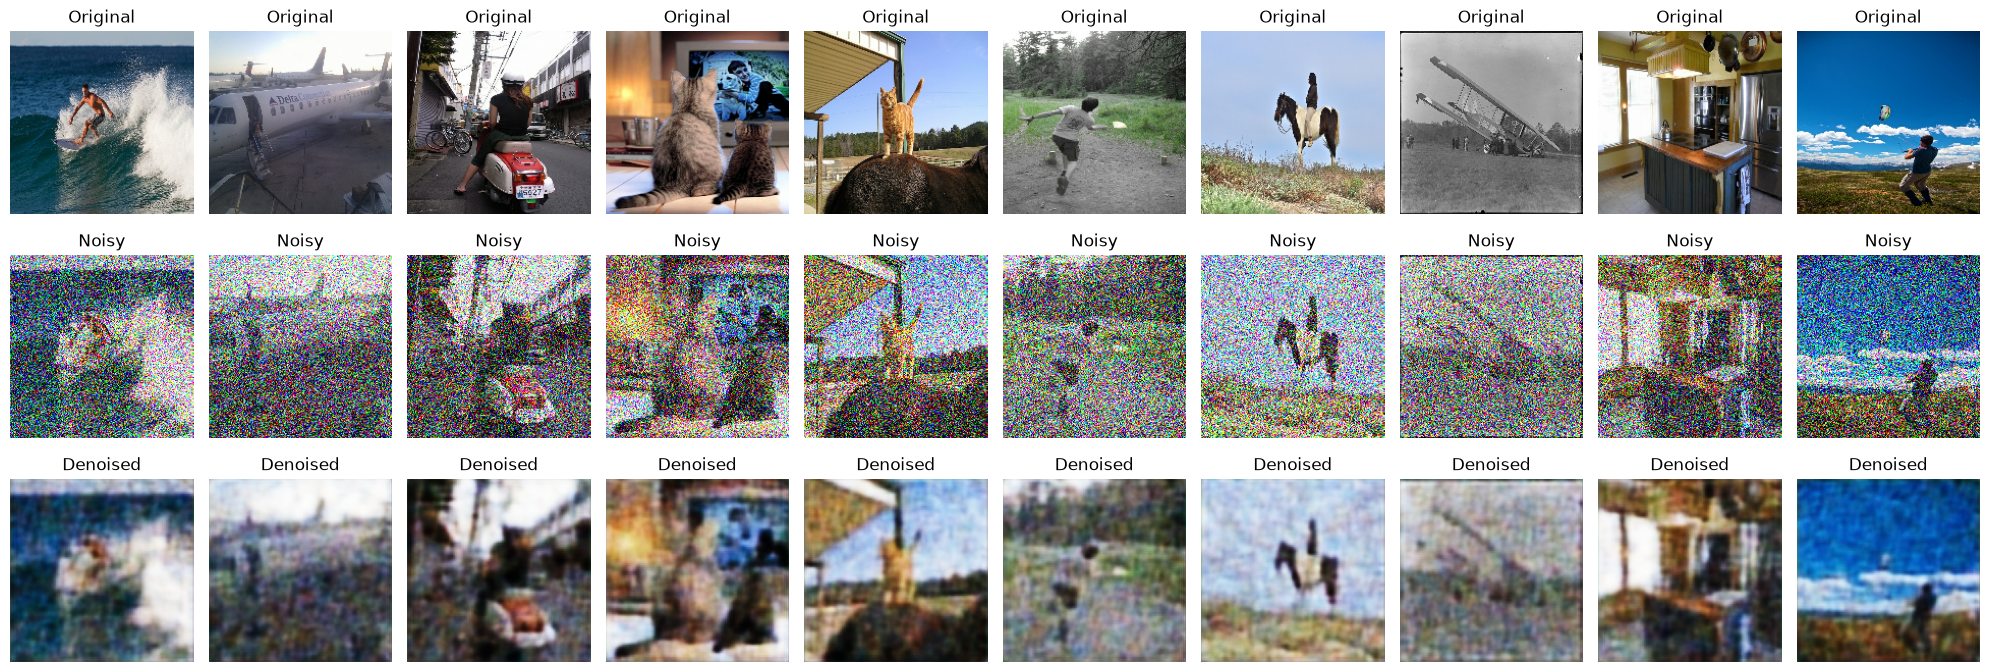

In [40]:
# Select the first 10 images
n = min(10, len(x_train_deliverable2))

# Reconstruct the noisy images using the trained autoencoder
x_train_denoisy_deliverable2 = autoencoder.predict(
    x_train_noisy_deliverable2[:n]
)

# Display Original, Noisy, and Denoisy images
plt.figure(figsize=(20, 7))

for i in range(n):
    # Original image
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_train_deliverable2[i])
    plt.title("Original")
    plt.axis("off")

    # Noisy image
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_train_noisy_deliverable2[i])
    plt.title("Noisy")
    plt.axis("off")

    # Denoised image
    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(x_train_denoisy_deliverable2[i])
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()

#case study

In [41]:
files2_teste = r"C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste"
noisy_dir2 = pathlib.Path(files2_teste)
if (noisy_dir2 / "Dataset").exists():
    noisy_dir2 = noisy_dir2 / "Dataset"
print (noisy_dir2)

C:\Users\ferge\OneDrive - Association Cesi Viacesi mail\Documents\Data Science Project\teste


In [42]:
# Load images from the test dataset
images_teste = tf.keras.utils.image_dataset_from_directory(
    noisy_dir2,
    labels=None,
    image_size=(image_h, image_w),
    batch_size=32,
    color_mode="rgb",
    shuffle=True,
    seed=False
)

Found 9 files.


In [43]:
# Normalize pixel values from [0, 255] to [0, 1]
normalization_layer = tf.keras.layers.Rescaling(1.0/255.0)
images_teste_normalized = images_teste.map(normalization_layer)

# Convert the dataset into a NumPy array
x_train_deliverable2_teste = np.concatenate([batch.numpy() for batch in images_teste_normalized],axis=0)
print("Test images:", x_train_deliverable2_teste.shape)

# Add Gaussian noise
noise_factor = 0.5
x_train_noisy_deliverable2_teste = (x_train_deliverable2_teste + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_train_deliverable2_teste.shape))

# Keep pixel values between 0 and 1
x_train_noisy_deliverable2_teste = np.clip(x_train_noisy_deliverable2_teste, 0.0, 1.0)
print("Original test images:", x_train_deliverable2_teste.shape)
print("Noisy test images:", x_train_noisy_deliverable2_teste.shape)

Test images: (9, 180, 180, 3)
Original test images: (9, 180, 180, 3)
Noisy test images: (9, 180, 180, 3)


In [44]:
# Denoise the test images using the trained autoencoder
x_train_denoisy_deliverable2_teste = autoencoder.predict(x_train_noisy_deliverable2_teste)
print("Denoised test images:", x_train_denoisy_deliverable2_teste.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 359ms/step
Denoised test images: (9, 180, 180, 3)


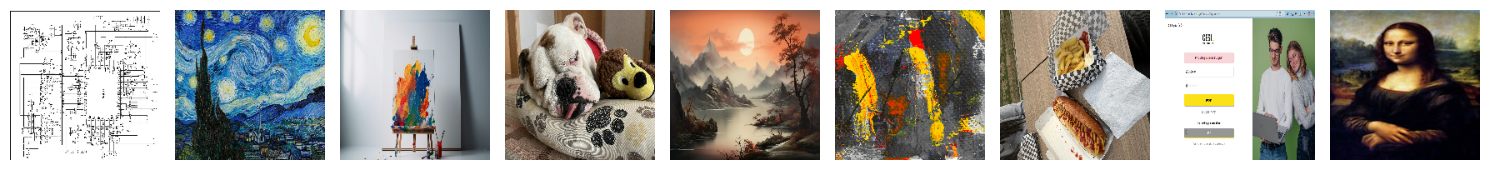

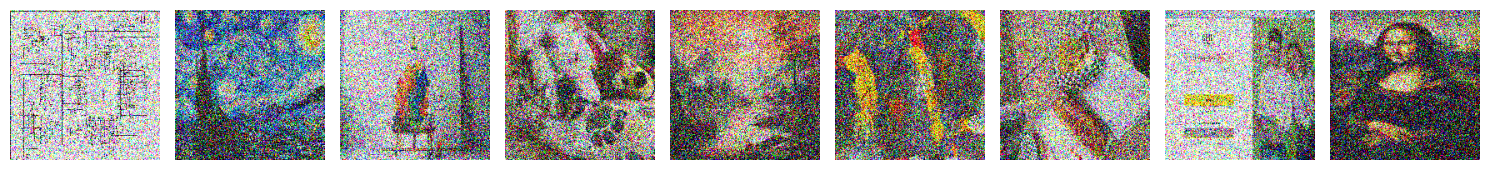

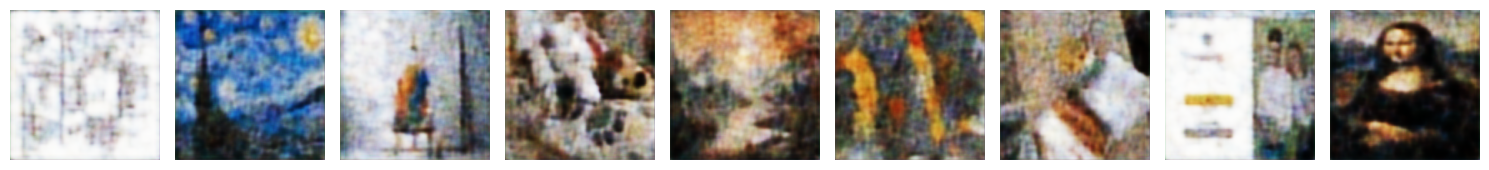

In [45]:
# Original images
display_image(x_train_deliverable2_teste,n=len(x_train_deliverable2_teste))     
# Noisy images
display_image(x_train_noisy_deliverable2_teste,n=len(x_train_noisy_deliverable2_teste))
# Denoised images
display_image(x_train_denoisy_deliverable2_teste,n=len(x_train_denoisy_deliverable2_teste))

In [47]:
#improvement